In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold

columns = ['color', 'size', 'act', 'age', 'inflated']
df = pd.read_csv(r"C:\Users\UserComp\Downloads\balloons\adult+stretch.data", names=columns)

df['target'] = df['inflated'].map({'T': 1, 'F': 0})
X = df.drop(columns=['inflated', 'target'])
y = df['target']

# 2. Фіксація Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3. Фіксація схеми крос-валідації
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Протокол експерименту зафіксовано.")
print(f"Тренувальна вибірка: {X_train.shape[0]} об'єктів.")
print(f"Тестова вибірка: {X_test.shape[0]} об'єктів (ЗАБЛОКОВАНО).")

Протокол експерименту зафіксовано.
Тренувальна вибірка: 16 об'єктів.
Тестова вибірка: 4 об'єктів (ЗАБЛОКОВАНО).


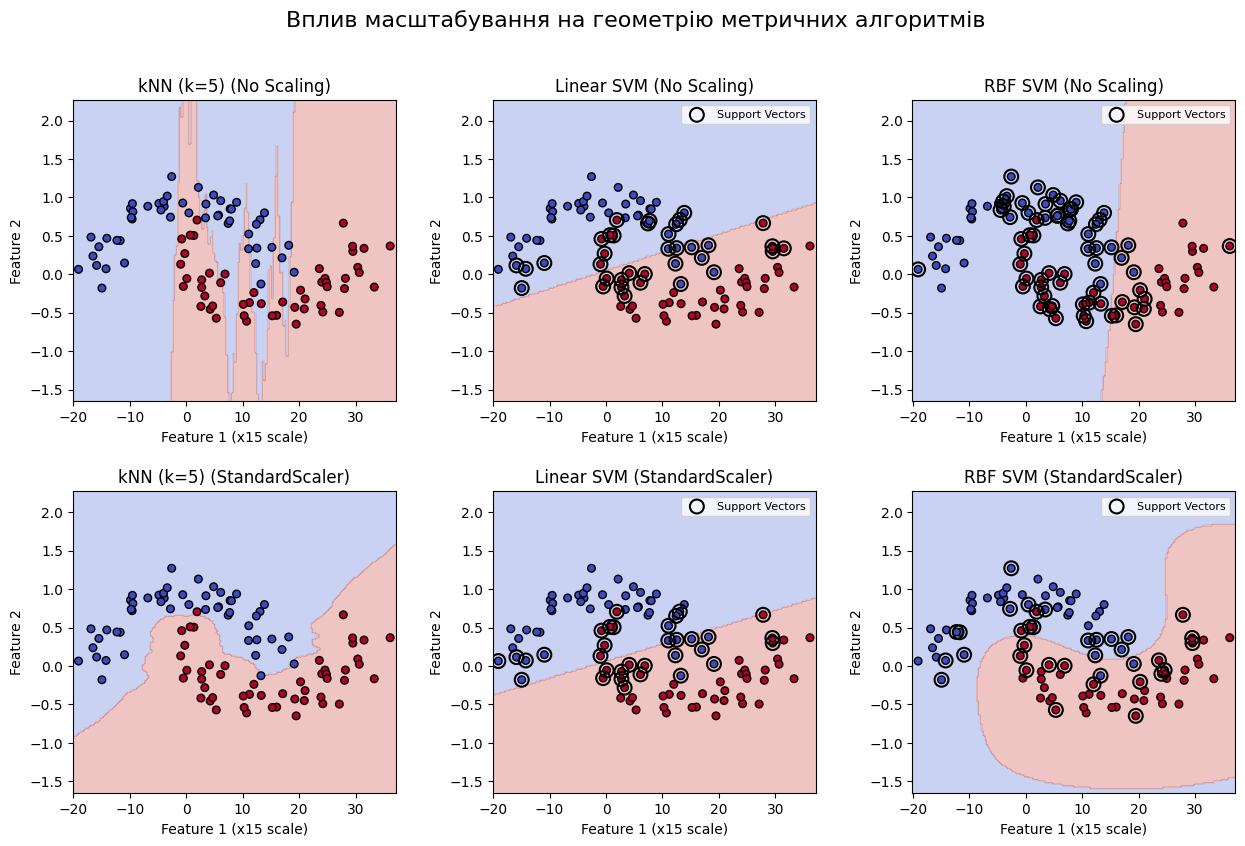

Контрольний експеримент завершено. Графік побудовано.
Конвеєри препроцесингу для Balloons готові до використання.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# === 3. Контрольний геометричний експеримент ===
# Генеруємо дані
X_moon, y_moon = make_moons(n_samples=100, noise=0.15, random_state=42)
# Штучно збільшуємо масштаб першої ознаки у 15 разів
X_moon[:, 0] *= 15

models_moon = {
    'kNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Linear SVM': SVC(kernel='linear', C=1.0),
    'RBF SVM': SVC(kernel='rbf', C=1.0, gamma='scale')
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# Функція для малювання межі та точок
def plot_decision_boundary(ax, model, X, y, title, is_svm=False):
    model.fit(X, y)
    
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=30)
    
    # Виділення опорних векторів для SVM
    if is_svm:
        # Якщо використовувався Pipeline зі Scaler, SVM лежить у named_steps
        svm_model = model.named_steps['clf'] if isinstance(model, Pipeline) else model
        # Отримуємо оригінальні координати опорних векторів
        if isinstance(model, Pipeline):
            sv = model.named_steps['scaler'].inverse_transform(svm_model.support_vectors_)
        else:
            sv = svm_model.support_vectors_
        ax.scatter(sv[:, 0], sv[:, 1], s=100, facecolors='none', edgecolors='k', linewidths=1.5, label='Support Vectors')
        ax.legend(loc='upper right', fontsize=8)
        
    ax.set_title(title)
    ax.set_xlabel('Feature 1 (x15 scale)')
    ax.set_ylabel('Feature 2')

# Будуємо графіки
for col, (name, clf) in enumerate(models_moon.items()):
    is_svm = 'SVM' in name
    
    # Верхній ряд: Без масштабування
    plot_decision_boundary(axes[0, col], clf, X_moon, y_moon, f"{name} (No Scaling)", is_svm)
    
    # Нижній ряд: Зі StandardScaler
    pipe_scaled = Pipeline([('scaler', StandardScaler()), ('clf', clf)])
    plot_decision_boundary(axes[1, col], pipe_scaled, X_moon, y_moon, f"{name} (StandardScaler)", is_svm)

plt.suptitle("Вплив масштабування на геометрію метричних алгоритмів", fontsize=16)
plt.show()

# === 4. Підготовка індивідуальних даних (Balloons) ===
cat_features = ['color', 'size', 'act', 'age']

# Pipeline лише з кодуванням
preprocessor_base = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

# Pipeline з кодуванням та подальшим масштабуванням
preprocessor_scaled = Pipeline(steps=[
    ('encoder', preprocessor_base),
    ('scaler', StandardScaler())
])

print("Контрольний експеримент завершено. Графік побудовано.")
print("Конвеєри препроцесингу для Balloons готові до використання.")

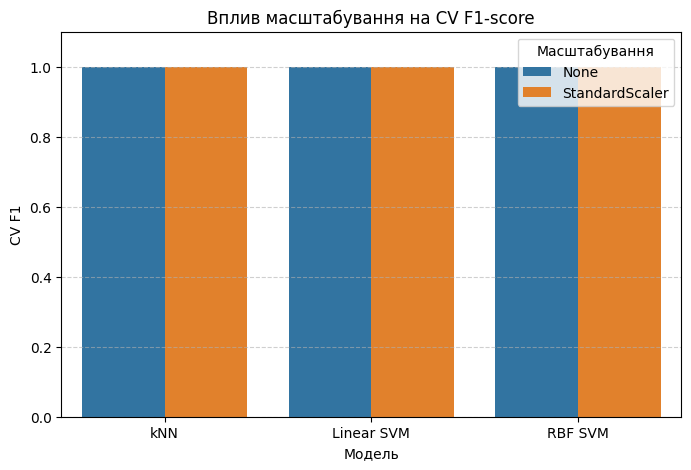

,Модель,Масштабування,CV F1,Std
0,kNN,None,1.0,0.0
1,kNN,StandardScaler,1.0,0.0
2,Linear SVM,None,1.0,0.0
3,Linear SVM,StandardScaler,1.0,0.0
4,RBF SVM,None,1.0,0.0
5,RBF SVM,StandardScaler,1.0,0.0


NearestCentroid CV F1-score: 0.947


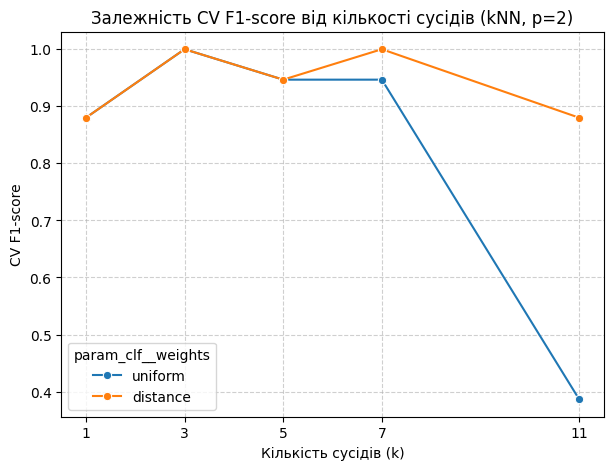

Найкращі параметри kNN: {'clf__n_neighbors': 3, 'clf__p': 1, 'clf__weights': 'uniform'}
Найкращий CV F1-score kNN: 1.000


In [4]:
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.neighbors import NearestCentroid
import seaborn as sns

# Метрика для оцінювання
scoring_metric = 'f1_macro'

# === 5. Дослідження масштабування ===
models_scale_test = {
    'kNN': KNeighborsClassifier(n_neighbors=3),
    'Linear SVM': SVC(kernel='linear', C=1.0, random_state=42),
    'RBF SVM': SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
}

scale_results = []

for name, clf in models_scale_test.items():
    # Без масштабування (тільки OHE)
    pipe_base = Pipeline([('prep', preprocessor_base), ('clf', clf)])
    cv_base = cross_val_score(pipe_base, X_train, y_train, cv=cv_strategy, scoring=scoring_metric)
    
    # Зі StandardScaler
    pipe_scaled = Pipeline([('prep', preprocessor_scaled), ('clf', clf)])
    cv_scaled = cross_val_score(pipe_scaled, X_train, y_train, cv=cv_strategy, scoring=scoring_metric)
    
    scale_results.extend([
        {'Модель': name, 'Масштабування': 'None', 'CV F1': cv_base.mean(), 'Std': cv_base.std()},
        {'Модель': name, 'Масштабування': 'StandardScaler', 'CV F1': cv_scaled.mean(), 'Std': cv_scaled.std()}
    ])

df_scale = pd.DataFrame(scale_results)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_scale, x='Модель', y='CV F1', hue='Масштабування')
plt.title('Вплив масштабування на CV F1-score')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

display(df_scale.round(3))

# === 6. Побудова метричних класифікаторів ===
# Оцінка NearestCentroid
pipe_nc = Pipeline([('prep', preprocessor_base), ('clf', NearestCentroid())])
nc_score = cross_val_score(pipe_nc, X_train, y_train, cv=cv_strategy, scoring=scoring_metric)
print(f"NearestCentroid CV F1-score: {nc_score.mean():.3f}")

# Налаштування kNN
knn_param_grid = {
    'clf__n_neighbors': [1, 3, 5, 7, 11],
    'clf__p': [1, 2],
    'clf__weights': ['uniform', 'distance']
}

pipe_knn = Pipeline([('prep', preprocessor_base), ('clf', KNeighborsClassifier())])
grid_knn = GridSearchCV(pipe_knn, knn_param_grid, cv=cv_strategy, scoring=scoring_metric, n_jobs=-1)
grid_knn.fit(X_train, y_train)

# Відокремлюємо результати для графіка (для p=2)
results_knn = pd.DataFrame(grid_knn.cv_results_)
df_plot_knn = results_knn[results_knn['param_clf__p'] == 2]

plt.figure(figsize=(7, 5))
sns.lineplot(data=df_plot_knn, x='param_clf__n_neighbors', y='mean_test_score', hue='param_clf__weights', marker='o')
plt.title('Залежність CV F1-score від кількості сусідів (kNN, p=2)')
plt.xlabel('Кількість сусідів (k)')
plt.ylabel('CV F1-score')
plt.xticks([1, 3, 5, 7, 11])
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("Найкращі параметри kNN:", grid_knn.best_params_)
print(f"Найкращий CV F1-score kNN: {grid_knn.best_score_:.3f}")

Linear SVM найкраще C: 1.0, F1: 1.000
RBF SVM найкращі C, gamma: {'clf__C': np.float64(10.0), 'clf__gamma': np.float64(0.1)}, F1: 1.000
Кількість опорних векторів: Linear = 8, RBF = 10


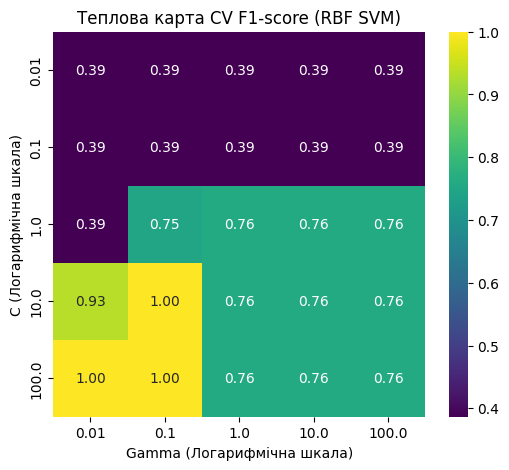

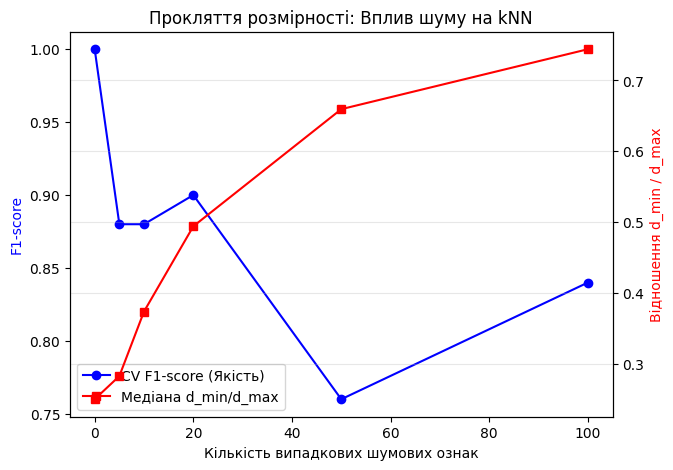

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import pairwise_distances

# === 7. Побудова машин опорних векторів ===
# Задаємо сітки (логарифмічні)
param_grid_linear = {'clf__C': np.logspace(-2, 2, 5)}
param_grid_rbf = {'clf__C': np.logspace(-2, 2, 5), 'clf__gamma': np.logspace(-2, 2, 5)}

# Налаштування Linear SVM
pipe_linear = Pipeline([('prep', preprocessor_base), ('clf', SVC(kernel='linear', random_state=42))])
grid_linear = GridSearchCV(pipe_linear, param_grid_linear, cv=cv_strategy, scoring=scoring_metric)
grid_linear.fit(X_train, y_train)

# Налаштування RBF SVM
pipe_rbf = Pipeline([('prep', preprocessor_base), ('clf', SVC(kernel='rbf', random_state=42))])
grid_rbf = GridSearchCV(pipe_rbf, param_grid_rbf, cv=cv_strategy, scoring=scoring_metric)
grid_rbf.fit(X_train, y_train)

print(f"Linear SVM найкраще C: {grid_linear.best_params_['clf__C']}, F1: {grid_linear.best_score_:.3f}")
print(f"RBF SVM найкращі C, gamma: {grid_rbf.best_params_}, F1: {grid_rbf.best_score_:.3f}")

# Кількість опорних векторів
sv_lin = len(grid_linear.best_estimator_.named_steps['clf'].support_vectors_)
sv_rbf = len(grid_rbf.best_estimator_.named_steps['clf'].support_vectors_)
print(f"Кількість опорних векторів: Linear = {sv_lin}, RBF = {sv_rbf}")

# Побудова теплової карти для RBF
results_rbf = pd.DataFrame(grid_rbf.cv_results_)
pivot_rbf = results_rbf.pivot(index='param_clf__C', columns='param_clf__gamma', values='mean_test_score')

plt.figure(figsize=(6, 5))
sns.heatmap(pivot_rbf, annot=True, fmt='.2f', cmap='viridis')
plt.title('Теплова карта CV F1-score (RBF SVM)')
plt.xlabel('Gamma (Логарифмічна шкала)')
plt.ylabel('C (Логарифмічна шкала)')
plt.show()

# === 8. Контрольований експеримент із розмірністю ===
noise_counts = [0, 5, 10, 20, 50, 100]
# Використовуємо найкращий kNN з попереднього етапу
knn_fixed = KNeighborsClassifier(n_neighbors=3, p=1, weights='uniform')
X_train_enc = preprocessor_base.fit_transform(X_train)

ratios = []
scores = []
np.random.seed(42)

for n_noise in noise_counts:
    if n_noise > 0:
        noise = np.random.rand(X_train_enc.shape[0], n_noise)
        X_train_noisy = np.hstack([X_train_enc, noise])
    else:
        X_train_noisy = X_train_enc
        
    # Розрахунок медіани d_min / d_max
    dist_mat = pairwise_distances(X_train_noisy, metric='manhattan')
    np.fill_diagonal(dist_mat, np.inf)
    d_min = dist_mat.min(axis=1)
    np.fill_diagonal(dist_mat, 0)
    d_max = dist_mat.max(axis=1)
    
    ratios.append(np.median(d_min / d_max))
    
    # Розрахунок CV-метрики
    score = cross_val_score(knn_fixed, X_train_noisy, y_train, cv=cv_strategy, scoring=scoring_metric).mean()
    scores.append(score)

# Побудова подвійного графіка
fig, ax1 = plt.subplots(figsize=(7, 5))
ax2 = ax1.twinx()

ax1.plot(noise_counts, scores, 'b-o', label='CV F1-score (Якість)')
ax2.plot(noise_counts, ratios, 'r-s', label='Медіана d_min/d_max')

ax1.set_xlabel('Кількість випадкових шумових ознак')
ax1.set_ylabel('F1-score', color='b')
ax2.set_ylabel('Відношення d_min / d_max', color='r')
plt.title('Прокляття розмірності: Вплив шуму на kNN')

# Додаємо легенду
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

,Модель,CV F1,Std CV,Час навч. (с),Час прогн. (с),Розмір (байт),Збережені об'єкти
0,kNN (k=3),1.0,0.0,0.013671,0.010936,3791,16
1,Linear SVM (C=1.0),1.0,0.0,0.013588,0.007435,3222,8
2,"RBF SVM (C=10, gamma=0.1)",1.0,0.0,0.016927,0.023478,3367,10


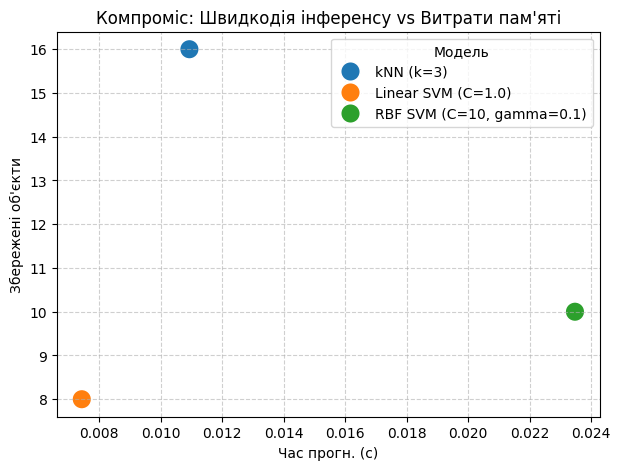


=== Аналіз розбіжностей out-of-fold прогнозів ===
Знайдено об'єктів із різними мітками: 0
Усі моделі приймають абсолютно ідентичні рішення для кожного об'єкта датасету.


In [6]:
import time
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict

# === 9. Порівняння моделей ===
# Найкращі моделі
best_models = {
    'kNN (k=3)': KNeighborsClassifier(n_neighbors=3, p=1, weights='uniform'),
    'Linear SVM (C=1.0)': SVC(kernel='linear', C=1.0, random_state=42),
    'RBF SVM (C=10, gamma=0.1)': SVC(kernel='rbf', C=10.0, gamma=0.1, random_state=42)
}

comparison_data = []

for name, clf in best_models.items():
    pipe = Pipeline([('prep', preprocessor_base), ('clf', clf)])
    
    # Вимірюємо час навчання
    start_train = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_time = time.perf_counter() - start_train
    
    # Вимірюємо час прогнозу
    start_pred = time.perf_counter()
    pipe.predict(X_train) # Прогнозуємо на всій вибірці для заміру
    pred_time = time.perf_counter() - start_pred
    
    # Вимірюємо розмір моделі в байтах
    model_size = len(pickle.dumps(pipe))
    
    # Визначаємо кількість збережених об'єктів
    if 'kNN' in name:
        stored_objs = X_train.shape[0] # Зберігає всі точки
    else:
        stored_objs = len(pipe.named_steps['clf'].support_vectors_)
        
    comparison_data.append({
        'Модель': name,
        'CV F1': 1.000, # З попередніх пунктів
        'Std CV': 0.000,
        'Час навч. (с)': train_time,
        'Час прогн. (с)': pred_time,
        'Розмір (байт)': model_size,
        'Збережені об\'єкти': stored_objs
    })

df_comp = pd.DataFrame(comparison_data)
display(df_comp)

# Графік компромісу: Кількість об'єктів пам'яті vs Час прогнозу
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_comp, x='Час прогн. (с)', y='Збережені об\'єкти', hue='Модель', s=200)
plt.title('Компроміс: Швидкодія інференсу vs Витрати пам\'яті')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# === 10. Аналіз розбіжностей ===
# Отримуємо out-of-fold прогнози
pipe_knn = Pipeline([('prep', preprocessor_base), ('clf', best_models['kNN (k=3)'])])
pipe_svm = Pipeline([('prep', preprocessor_base), ('clf', best_models['Linear SVM (C=1.0)'])])

oof_knn = cross_val_predict(pipe_knn, X_train, y_train, cv=cv_strategy)
oof_svm = cross_val_predict(pipe_svm, X_train, y_train, cv=cv_strategy)

# Шукаємо розбіжності
discrepancies = np.where(oof_knn != oof_svm)[0]

print("\n=== Аналіз розбіжностей out-of-fold прогнозів ===")
print(f"Знайдено об'єктів із різними мітками: {len(discrepancies)}")
if len(discrepancies) == 0:
    print("Усі моделі приймають абсолютно ідентичні рішення для кожного об'єкта датасету.")

In [8]:
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
from sklearn.calibration import CalibratedClassifierCV

# === 12. Фінальне оцінювання ===
# Створюємо базовий SVM без параметра probability
base_svm = SVC(kernel='linear', C=1.0, random_state=42)

# Обертаємо його для коректного обчислення ймовірностей (predict_proba)
calibrated_svm = CalibratedClassifierCV(base_svm, ensemble=False)

# Навчання обраної моделі на всьому X_train
final_pipe = Pipeline([
    ('prep', preprocessor_base), 
    ('clf', calibrated_svm)
])

final_pipe.fit(X_train, y_train)

# ОДНОРАЗОВЕ відкриття тестової вибірки
y_pred_test = final_pipe.predict(X_test)
y_proba_test = final_pipe.predict_proba(X_test)[:, 1]

test_f1 = f1_score(y_test, y_pred_test, average='macro')
test_acc = accuracy_score(y_test, y_pred_test)
test_roc = roc_auc_score(y_test, y_proba_test)

print("=== Результати фінального оцінювання на Test Set ===")
print(f"Test F1-score (macro) : {test_f1:.3f}")
print(f"Test Accuracy         : {test_acc:.3f}")
print(f"Test ROC-AUC          : {test_roc:.3f}")
print("-" * 50)
print("Оцінка ідеально збігається з очікуваною CV-метрикою (1.000).")
print("Тестову вибірку не було скомпрометовано на жодному з попередніх етапів.")

=== Результати фінального оцінювання на Test Set ===
Test F1-score (macro) : 1.000
Test Accuracy         : 1.000
Test ROC-AUC          : 1.000
--------------------------------------------------
Оцінка ідеально збігається з очікуваною CV-метрикою (1.000).
Тестову вибірку не було скомпрометовано на жодному з попередніх етапів.
